<a href="https://colab.research.google.com/github/withfablue/ISLP/blob/main/Ch12_Unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install ISLP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ISLP import load_data

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 43.0 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4120 sha256=484fae3b50e39b5301a8acf0b01bbe083f5a3b550d959feb2c818a6f1e474b03
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma


In [3]:
from sklearn.cluster import (KMeans, AgglomerativeClustering)
from scipy.cluster.hierarchy import (dendrogram, cut_tree)
from ISLP.cluster import compute_linkage

PCA

In [4]:
USArrests = get_rdataset('USArrests').data
USArrests

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6
Colorado,7.9,204,78,38.7
Connecticut,3.3,110,77,11.1
Delaware,5.9,238,72,15.8
Florida,15.4,335,80,31.9


In [5]:
USArrests.columns

Index(['Murder', 'Assault', 'UrbanPop', 'Rape'], dtype='object')

In [6]:
USArrests.mean()

,0
Murder,7.788
Assault,170.760
UrbanPop,65.540
Rape,21.232


In [7]:
USArrests.var()

,0
Murder,18.970465
Assault,6945.165714
UrbanPop,209.518776
Rape,87.729159


In [10]:
scaler = StandardScaler(with_std=True, with_mean=True)
USArrests_scaled = scaler.fit_transform(USArrests)


In [11]:
pcaUS = PCA()

In [12]:
pcaUS.fit(USArrests_scaled)

PCA()

In [13]:
pcaUS.mean_

array([-7.10542736e-17,  1.38777878e-16, -4.39648318e-16,  8.59312621e-16])

In [14]:
scores = pcaUS.transform(USArrests_scaled)

In [15]:
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

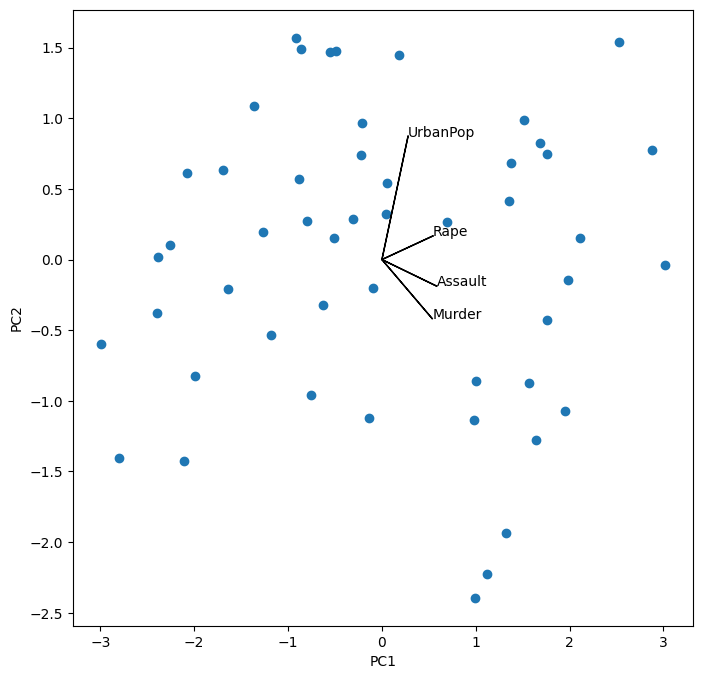

In [16]:
# biplot
i, j = 0, 1  # 어떤 주성분들을 선택할까
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(scores[:,0], scores[:,1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
  ax.arrow(0, 0, pcaUS.components_[i, k], pcaUS.components_[j, k])
  ax.text(pcaUS.components_[i,k],
          pcaUS.components_[j,k],
          USArrests.columns[k])

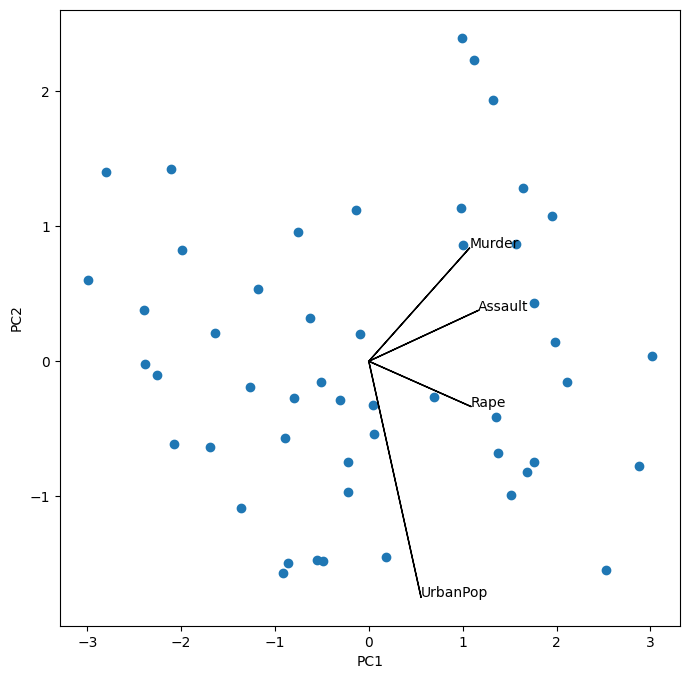

In [17]:
scale_Arrow = s_ = 2
scores[:,1] *= -1
pcaUS.components_[1] *= -1
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(scores[:,0], scores[:,1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
  ax.arrow(0, 0, s_*pcaUS.components_[i, k], s_*pcaUS.components_[j, k])
  ax.text(s_*pcaUS.components_[i,k],
          s_*pcaUS.components_[j,k],
          USArrests.columns[k])

In [18]:
scores.std(0, ddof=1)

array([1.5908673 , 1.00496987, 0.6031915 , 0.4206774 ])

In [20]:
pcaUS.explained_variance_

array([2.53085875, 1.00996444, 0.36383998, 0.17696948])

In [21]:
pcaUS.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

In [22]:
%%capture
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ticks = np.arange(pcaUS.n_components_)+1
ax = axes[0]
ax.plot(ticks, pcaUS.explained_variance_ratio_, marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)

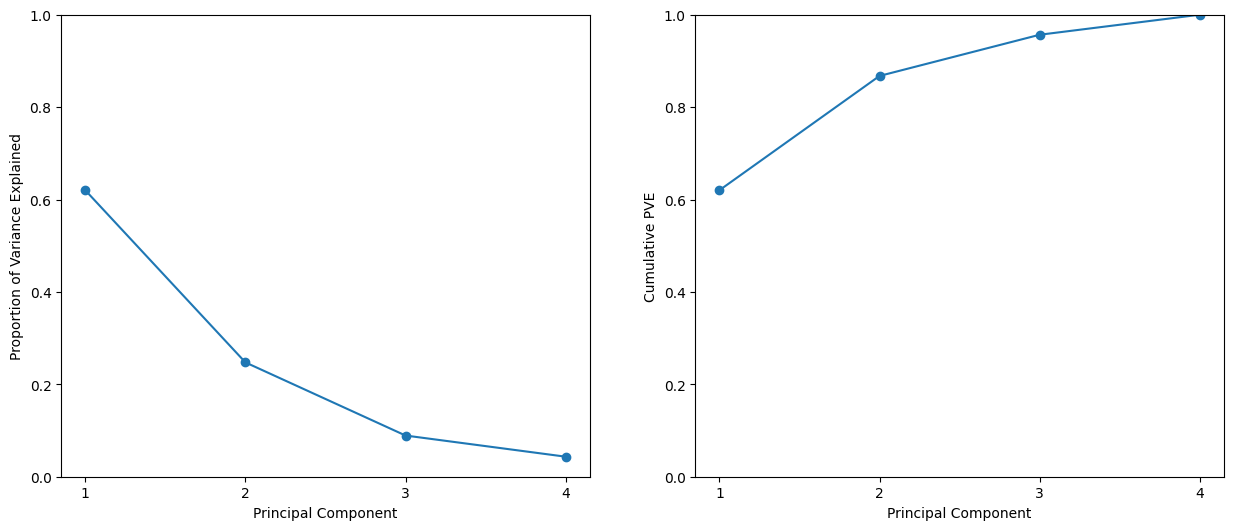

In [24]:
ax = axes[1]
ax.plot(ticks, pcaUS.explained_variance_ratio_.cumsum(), marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Cumulative PVE')
ax.set_ylim([0,1])
ax.set_xticks(ticks)
fig


In [25]:
# Matrix Completion
X = USArrests_scaled
U, D, V = np.linalg.svd(X, full_matrices=False)
U.shape, D.shape, V.shape


((50, 4), (4,), (4, 4))

In [27]:
V

array([[-0.53589947, -0.58318363, -0.27819087, -0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [ 0.34123273,  0.26814843,  0.37801579, -0.81777791],
       [ 0.6492278 , -0.74340748,  0.13387773,  0.08902432]])

In [28]:
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [ 0.41818087,  0.1879856 , -0.87280619, -0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

In [29]:
(U * D[None,:])[:3]

array([[-0.98556588, -1.13339238,  0.44426879,  0.15626714],
       [-1.95013775, -1.07321326, -2.04000333, -0.43858344],
       [-1.76316354,  0.74595678, -0.05478082, -0.83465292]])

In [30]:
scores[:3]

array([[ 0.98556588,  1.13339238, -0.44426879, -0.15626714],
       [ 1.95013775,  1.07321326,  2.04000333,  0.43858344],
       [ 1.76316354, -0.74595678,  0.05478082,  0.83465292]])

In [31]:
n_omit = 20
np.random.seed(15)
r_idx = np.random.choice(np.arange(X.shape[0]), n_omit, replace=False)
c_idx = np.random.choice(np.arange(X.shape[1]), n_omit, replace=True)
Xna = X.copy()
Xna[r_idx, c_idx] = np.nan


In [32]:
def low_rank(X, M=1):
  U, D, V = np.linalg.svd(X)
  L = U[:, :M] * D[None, :M]
  return L.dot(V[:M])

In [33]:
Xhat = Xna.copy()
Xbar = np.nanmean(Xhat, axis=0)
Xhat[r_idx, c_idx] = Xbar[c_idx]

In [34]:
thresh = 1e-7
rel_err = 1
count=0
ismiss = np.isnan(Xna)
mssold = np.mean(Xhat[~ismiss]**2)
mss0 = np.mean(Xna[~ismiss]**2)


In [35]:
while rel_err > thresh:
  count += 1
  # 단계 2(a)
  Xapp = low_rank(Xhat, M=1)
  # 단계 2(b)
  Xhat[ismiss] = Xapp[ismiss]
  # 단계 2(c)
  mss = np.mean(((Xna-Xapp)[~ismiss])**2)
  rel_err = (mssold-mss) / mss0
  mssold = mss
  print("Iteration {0}, MSS {1:.3f}, Rel.Err {2:.2e}".format(count, mss, rel_err))

Iteration 1, MSS 0.395, Rel.Err 5.99e-01
Iteration 2, MSS 0.382, Rel.Err 1.33e-02
Iteration 3, MSS 0.381, Rel.Err 1.44e-03
Iteration 4, MSS 0.381, Rel.Err 1.79e-04
Iteration 5, MSS 0.381, Rel.Err 2.58e-05
Iteration 6, MSS 0.381, Rel.Err 4.22e-06
Iteration 7, MSS 0.381, Rel.Err 7.65e-07
Iteration 8, MSS 0.381, Rel.Err 1.48e-07
Iteration 9, MSS 0.381, Rel.Err 2.95e-08


In [36]:
np.corrcoef(Xapp[ismiss], X[ismiss])[0,1]

np.float64(0.7113567434297361)

Clustering

In [37]:
np.random.seed(0);
X = np.random.standard_normal((50,2));
X[:25,0] += 3;
X[25:,1] -= 4;

In [38]:
X

array([[ 4.76405235,  0.40015721],
       [ 3.97873798,  2.2408932 ],
       [ 4.86755799, -0.97727788],
       [ 3.95008842, -0.15135721],
       [ 2.89678115,  0.4105985 ],
       [ 3.14404357,  1.45427351],
       [ 3.76103773,  0.12167502],
       [ 3.44386323,  0.33367433],
       [ 4.49407907, -0.20515826],
       [ 3.3130677 , -0.85409574],
       [ 0.44701018,  0.6536186 ],
       [ 3.8644362 , -0.74216502],
       [ 5.26975462, -1.45436567],
       [ 3.04575852, -0.18718385],
       [ 4.53277921,  1.46935877],
       [ 3.15494743,  0.37816252],
       [ 2.11221425, -1.98079647],
       [ 2.65208785,  0.15634897],
       [ 4.23029068,  1.20237985],
       [ 2.61267318, -0.30230275],
       [ 1.95144703, -1.42001794],
       [ 1.29372981,  1.9507754 ],
       [ 2.49034782, -0.4380743 ],
       [ 1.74720464,  0.77749036],
       [ 1.38610215, -0.21274028],
       [-0.89546656, -3.6130975 ],
       [-0.51080514, -5.18063218],
       [-0.02818223, -3.57166813],
       [ 0.06651722,

In [39]:
kmeans = KMeans(n_clusters=2, random_state=2, n_init=20).fit(X)

In [40]:
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int32)

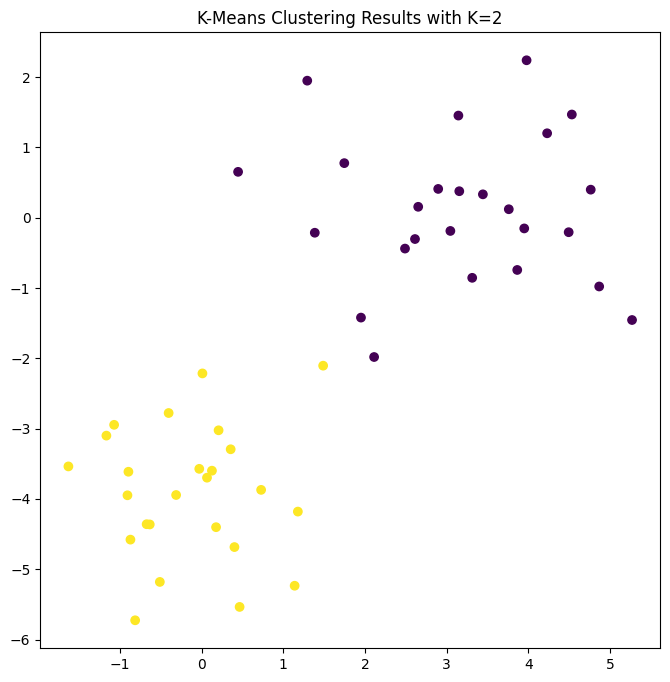

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(X[:,0], X[:,1], c=kmeans.labels_)
ax.set_title("K-Means Clustering Results with K=2");


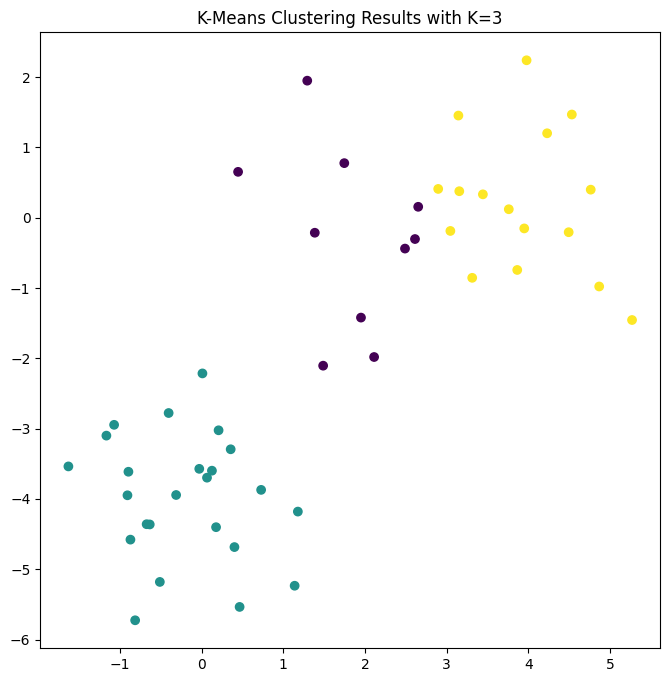

In [42]:
kmeans = KMeans(n_clusters=3, random_state=3, n_init=20).fit(X)
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(X[:,0], X[:,1], c=kmeans.labels_)
ax.set_title("K-Means Clustering Results with K=3");


In [43]:
kmeans1 = KMeans(n_clusters=3, random_state=3, n_init=1).fit(X)
kmeans20 = KMeans(n_clusters=3, random_state=3, n_init=20).fit(X);
kmeans1.inertia_, kmeans20.inertia_

(73.0857691644054, 72.67721071171229)

In [44]:
HClust = AgglomerativeClustering
hc_comp = HClust(distance_threshold=0,
                 n_clusters=None,
                 linkage='complete')
hc_comp.fit(X)

AgglomerativeClustering(distance_threshold=0, linkage='complete',
                        n_clusters=None)

In [45]:
hc_avg = HClust(distance_threshold=0,
                 n_clusters=None,
                 linkage='average');
hc_avg.fit(X)
hc_sing = HClust(distance_threshold=0,
                 n_clusters=None,
                 linkage='single');
hc_sing.fit(X);

In [48]:
D = np.zeros((X.shape[0], X.shape[0]));
for i in range(X.shape[0]):
  x_ = np.multiply.outer(np.ones(X.shape[0]), X[i])
  D[i] = np.sqrt(np.sum((X-x_)**2, 1));
hc_sing_pre = HClust(distance_threshold=0,
                     n_clusters=None,
                     metric='precomputed',
                     linkage='single')

hc_sing_pre.fit(D)

AgglomerativeClustering(distance_threshold=0, linkage='single',
                        metric='precomputed', n_clusters=None)

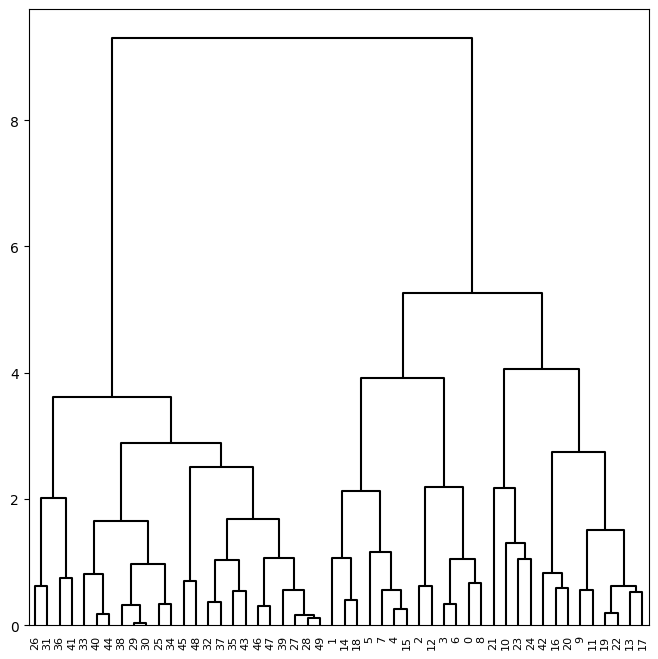

In [50]:
cargs = {'color_threshold':-np.inf, 'above_threshold_color':'black'}
linkage_comp = compute_linkage(hc_comp)
fig, ax = plt.subplots(1, 1, figsize=(8,8))
dendrogram(linkage_comp,
           ax=ax,
           **cargs);

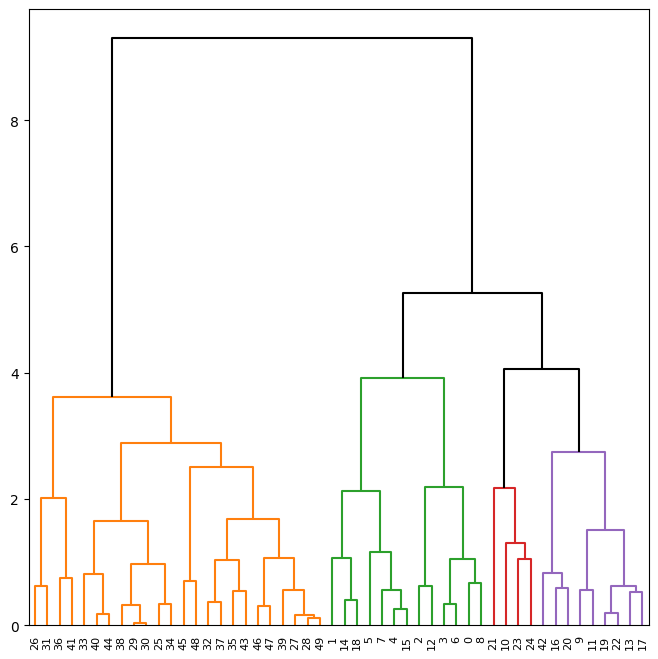

In [51]:
fig, ax = plt.subplots(figsize=(8,8))
dendrogram(linkage_comp,
           ax=ax,
           color_threshold=4,
           above_threshold_color='black');


In [52]:
cut_tree(linkage_comp, n_clusters=4).T

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 2,
        1, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 3,
        3, 3, 3, 3, 3, 3]])

In [53]:
cut_tree(linkage_comp, height=5)

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [1],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2]])

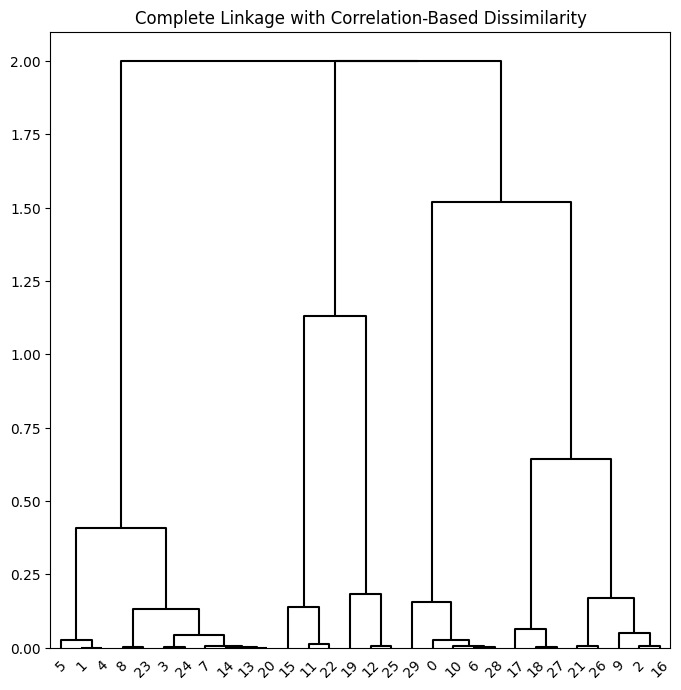

In [56]:
X = np.random.standard_normal((30, 3))
corD = 1 - np.corrcoef(X)
hc_cor = HClust(linkage='complete',
                distance_threshold=0,
                n_clusters=None,
                metric='precomputed')
hc_cor.fit(corD)
linkage_cor = compute_linkage(hc_cor)
fig, ax = plt.subplots(figsize=(8,8))
dendrogram(linkage_cor, ax=ax, **cargs)
ax.set_title("Complete Linkage with Correlation-Based Dissimilarity");

NCI60 dataset

In [57]:
NCI60 = load_data('NCI60')
nci_labs = NCI60['labels']
nci_data = NCI60['data']

In [58]:
nci_data.shape

(64, 6830)

In [59]:
nci_labs.value_counts()

,count
label,
RENAL,9
NSCLC,9
MELANOMA,8
BREAST,7
COLON,7
LEUKEMIA,6
OVARIAN,6
CNS,5
PROSTATE,2


In [61]:
# PCA
scaler = StandardScaler()
nci_scaled = scaler.fit_transform(nci_data)
nci_pca = PCA()
nci_scores = nci_pca.fit_transform(nci_scaled)

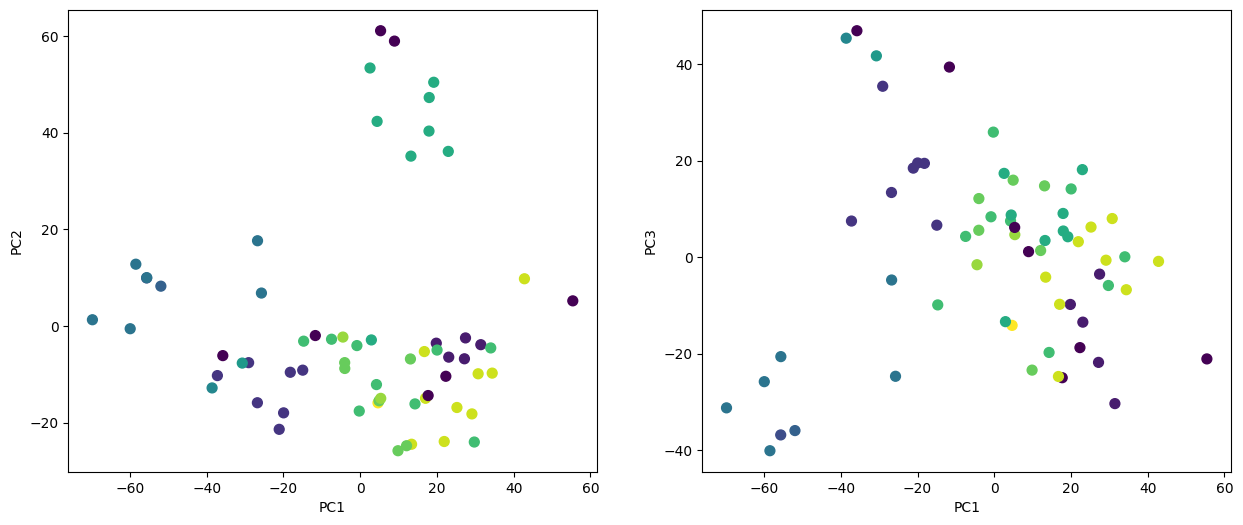

In [64]:
cancer_types = list(np.unique(nci_labs))
nci_groups = np.array([cancer_types.index(lab) for lab in nci_labs.values])
fig, axes = plt.subplots(1, 2, figsize=(15,6))
ax = axes[0]
ax.scatter(nci_scores[:,0], nci_scores[:,1], c=nci_groups, marker='o', s=50)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax = axes[1]
ax.scatter(nci_scores[:,0], nci_scores[:,2], c=nci_groups, marker='o', s=50)
ax.set_xlabel('PC1'); ax.set_ylabel('PC3');

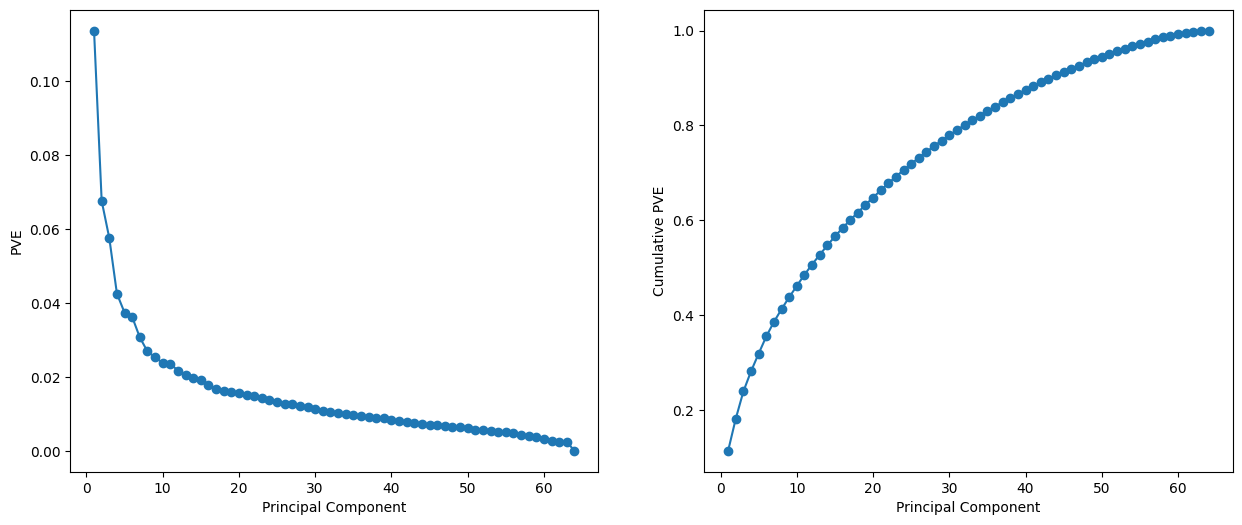

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(15,6))
ticks = np.arange(nci_pca.n_components_)+1
ax = axes[0]
ax.plot(ticks, nci_pca.explained_variance_ratio_, marker='o')
ax.set_xlabel('Principal Component');
ax.set_ylabel('PVE')
ax = axes[1]
ax.plot(ticks, nci_pca.explained_variance_ratio_.cumsum(), marker='o');
ax.set_xlabel('Principal Component')
ax.set_ylabel('Cumulative PVE');

In [68]:
# Clustering
def plot_nci(linkage, ax, cut=-np.inf):
  cargs = {'above_threshold_color':'black', 'color_threshold':cut}
  hc = HClust(n_clusters=None, distance_threshold=0, linkage=linkage.lower()).fit(nci_scaled)
  linkage_ = compute_linkage(hc)
  dendrogram(linkage_, ax=ax, labels=np.asarray(nci_labs), leaf_font_size=10, **cargs)
  ax.set_title('%s Linkage' % linkage)
  return hc


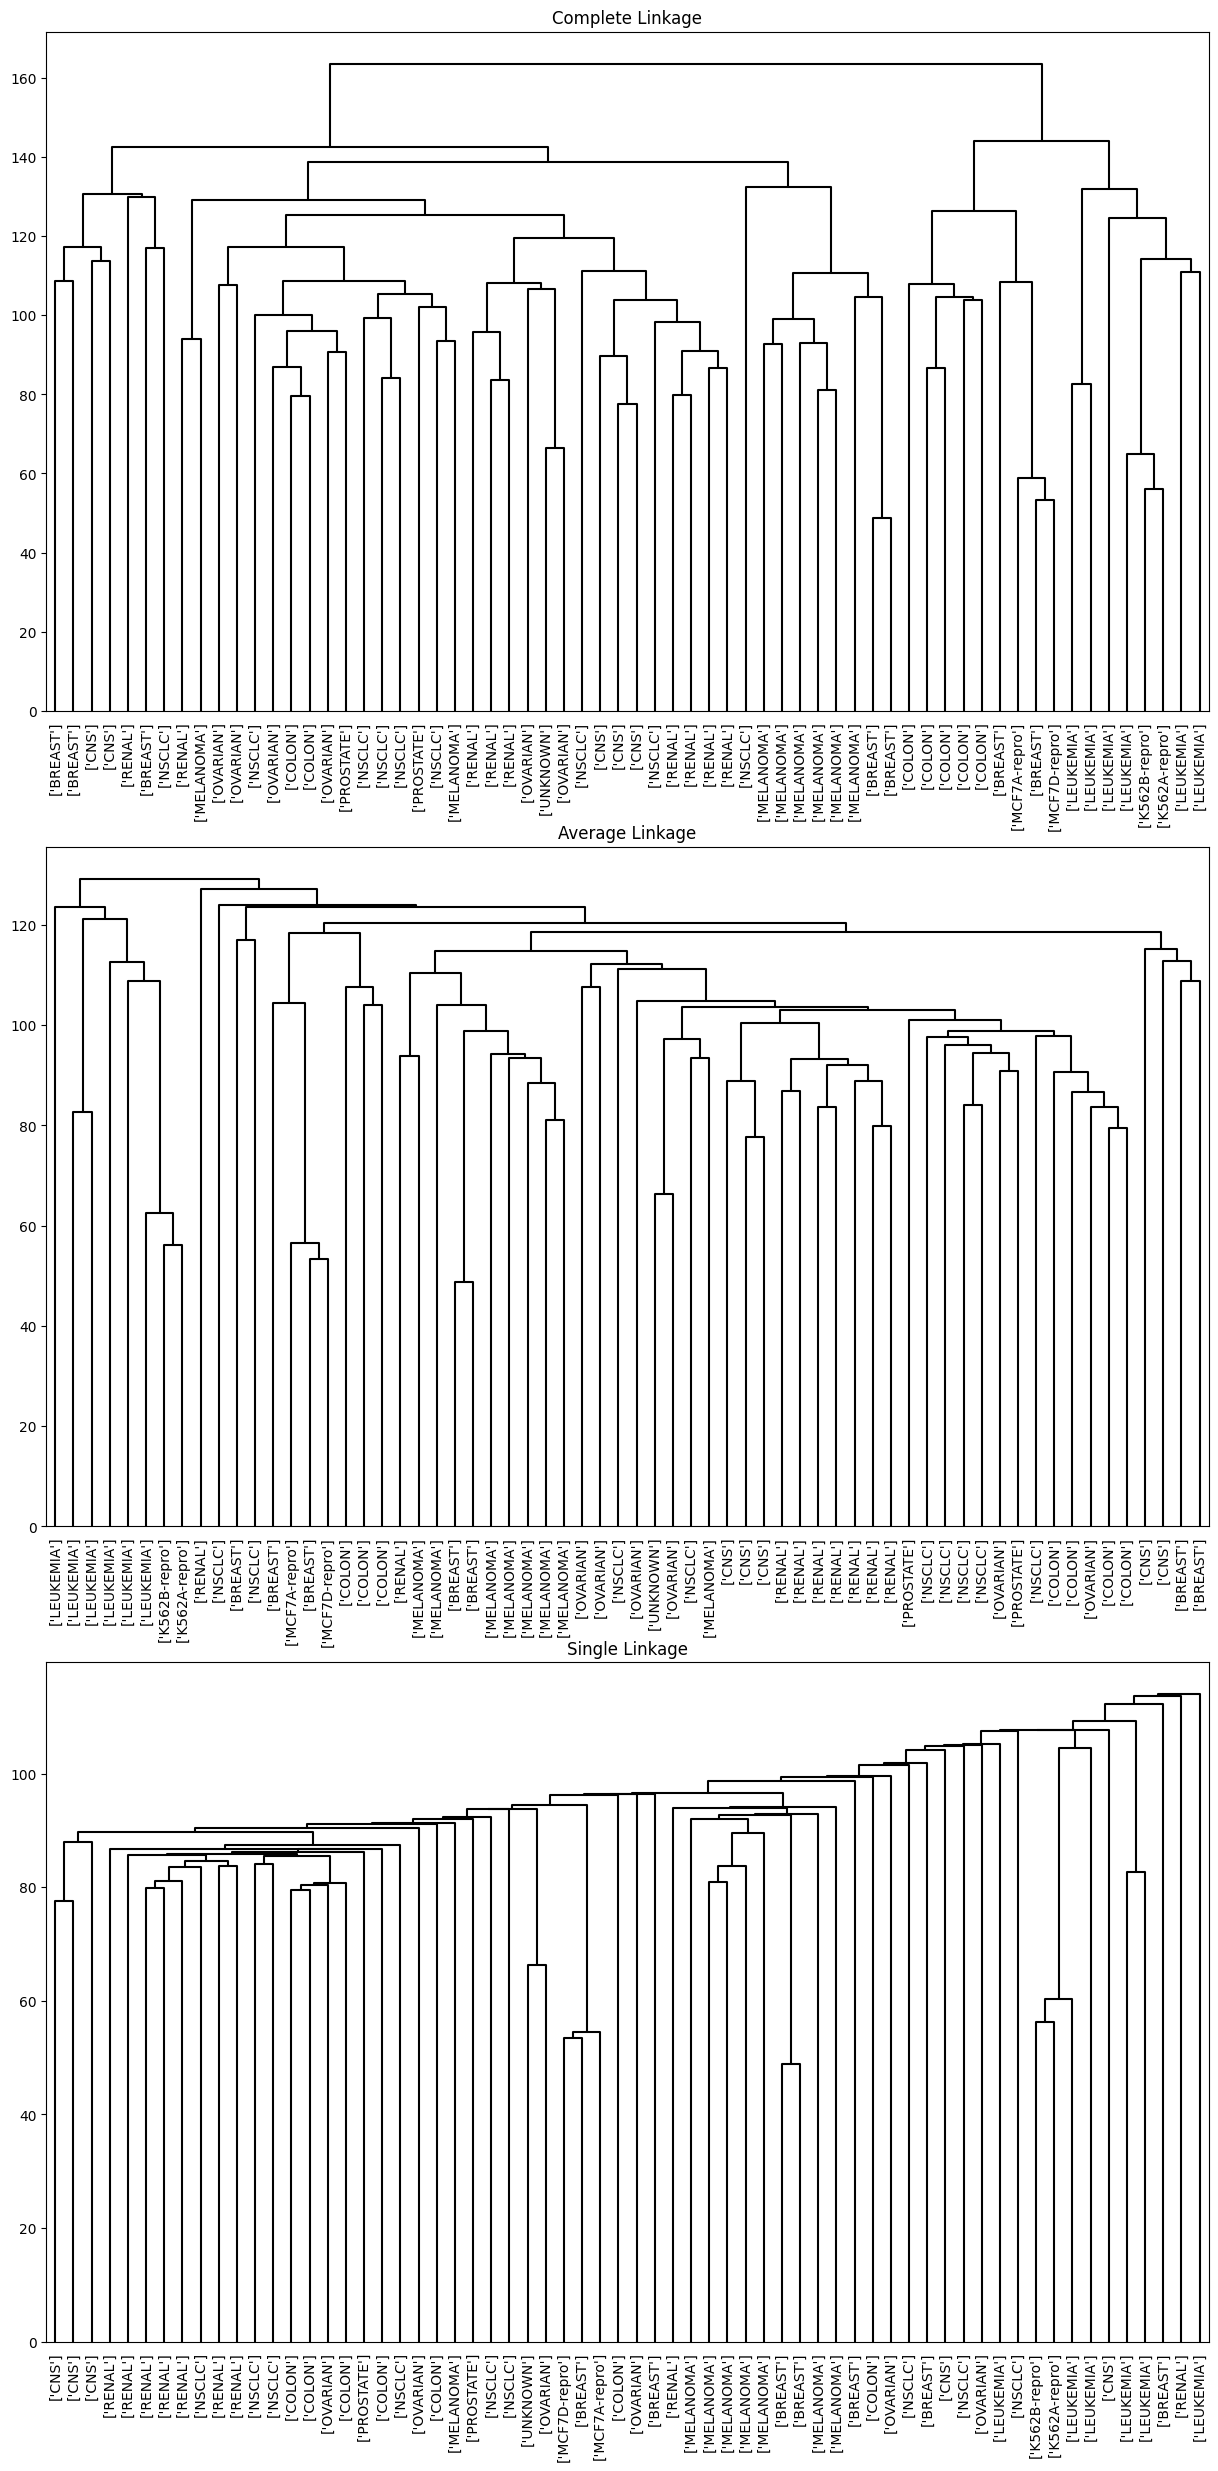

In [71]:
fig, axes = plt.subplots(3, 1, figsize=(15, 30))
ax=axes[0]; hc_comp = plot_nci('Complete', ax)
ax=axes[1]; hc_avg = plot_nci('Average', ax)
ax=axes[2]; hc_sing = plot_nci('Single', ax)


In [72]:
linkage_comp = compute_linkage(hc_comp)
comp_cut = cut_tree(linkage_comp, n_clusters=4).reshape(-1)
pd.crosstab(nci_labs['label'], pd.Series(comp_cut.reshape(-1), name='Complete'))

Complete,0,1,2,3
label,,,,
BREAST,2,3,0,2
CNS,3,2,0,0
COLON,2,0,0,5
K562A-repro,0,0,1,0
K562B-repro,0,0,1,0
LEUKEMIA,0,0,6,0
MCF7A-repro,0,0,0,1
MCF7D-repro,0,0,0,1
MELANOMA,8,0,0,0


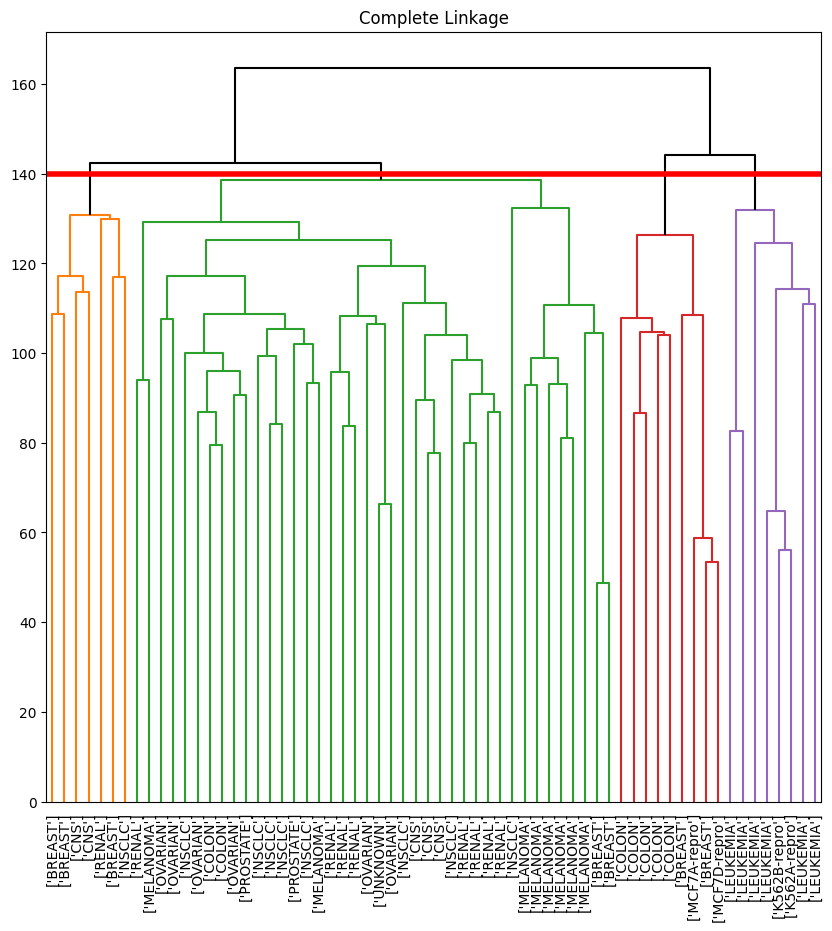

In [73]:
fig, ax = plt.subplots(figsize=(10,10))
plot_nci('Complete', ax, cut=140)
ax.axhline(140, c='r', lw=4)

In [74]:
nci_kmeans = KMeans(n_clusters=4, random_state=0, n_init=20).fit(nci_scaled)
pd.crosstab(pd.Series(comp_cut, name='HClust'),
            pd.Series(nci_kmeans.labels_, name='K-means'))

K-means,0,1,2,3
HClust,,,,
0,1,20,10,9
1,0,7,0,0
2,8,0,0,0
3,0,0,9,0


Complete-PCA,0,1,2,3
label,,,,
BREAST,0,5,0,2
CNS,2,3,0,0
COLON,7,0,0,0
K562A-repro,0,0,1,0
K562B-repro,0,0,1,0
LEUKEMIA,2,0,4,0
MCF7A-repro,0,0,0,1
MCF7D-repro,0,0,0,1
MELANOMA,1,7,0,0


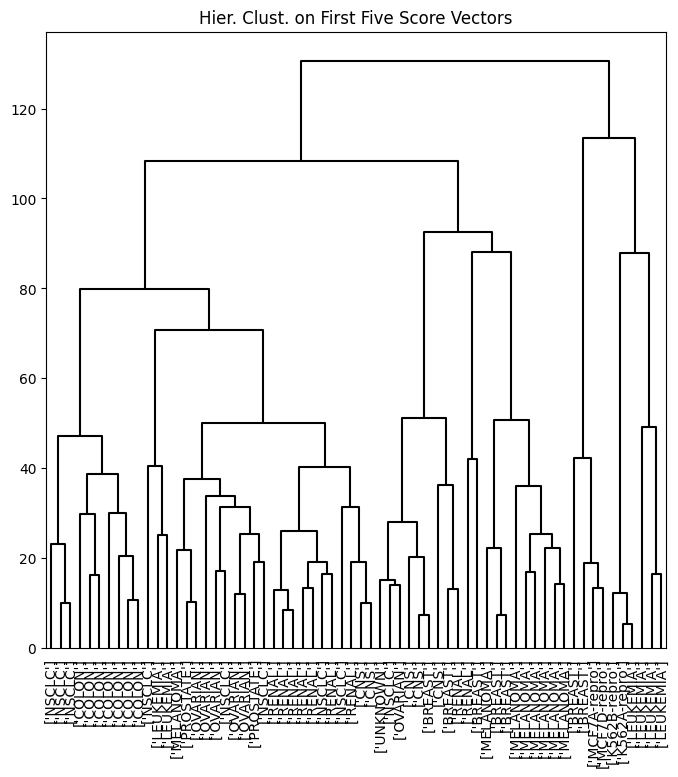

In [78]:
hc_pca = HClust(n_clusters=None, distance_threshold=0, linkage='complete').fit(nci_scores[:,:5])
linkage_pca = compute_linkage(hc_pca)
fig, ax = plt.subplots(figsize=(8,8))
dendrogram(linkage_pca, labels=np.asarray(nci_labs), leaf_font_size=10, ax=ax, **cargs)
ax.set_title("Hier. Clust. on First Five Score Vectors")
pca_labels = pd.Series(cut_tree(linkage_pca, n_clusters=4).reshape(-1), name='Complete-PCA')
pd.crosstab(nci_labs['label'], pca_labels)